# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

In [2]:
import json

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

# TODO:
1. Wikipedia harvest - Run as is for now, try to understand why it crushes near the end. **---------> DONE!**
2. Extract tables:
    - length between 3 to 10 **---------> DONE!**
    - table is square and parsed normally (no merged cells) **---------> DONE!**
    - full table **---------> DONE!**
    - remove some columns with no relevant data (empty or by keywords) **---------> DONE!**
3. Add to table extraction text titles and relevant paragraphs for the context. **---------> DONE!**
4. Cluster titles to remove similar options + take only one table per page. **---------> DONE!**
5. Create groups - all the table, try to see what is the main entity - return the column name, if they don't have one, discard the table and return 'None'. **---------> DONE!**
6. Create Questions
    - strategy injection, sample a subset of strategies in a shuffled order, if not possible than discard table.
    - make a function to extract the answer per question strategy --> create GT answer.
    - Add the 'group size' strategy.
    - constract the data samples.

### Havest Wikipedia pages with tables:

In [91]:
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiHarvester
# Initialize Wikipedia harvester
harvester = WikiHarvester()
# Run Phase 1 - Harvesting titles based on keywords
harvester.run_complete_harvest()
# Run Phase 2 - Filtering pages for tables
await harvester.filter_pages_async()

Harvesting Pages By Keywords:   0%|          | 0/233 [00:00<?, ?keyword/s]


TOTAL UNIQUE TITLES COLLECTED: 167913



Method,Keyword,Count
Prefix,List of cities,1537
Prefix,List of countries,1278
Prefix,List of towns,501
Prefix,List of villages,483
Prefix,List of districts,375
Prefix,List of municipalities,1021
Prefix,List of communes,194
Prefix,List of counties,259
Prefix,List of provinces,84
Prefix,List of territories,22


Filtering Pages with Tables:   0%|          | 0/167913 [00:00<?, ?page/s]


TOTAL PAGES WITH TABLES COLLECTED: 62306



In [93]:
save_json("table_titles", harvester.valid_titles)

In [3]:
table_titles = load_json("C:/Users/Daniel/Desktop/KnowledgeMaze/data_files/table_titles.json")

### Parse and filter Wikipedia tables:

In [271]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(table_titles)
validated_tables = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
cleaned_data = processor.process()

Pre-processing: cluster similar pages and discard similarities ---> 6426 pages discarded.


Extracting Tables:   0%|          | 0/55880 [00:00<?, ?Page/s]

Starting Extraction: 55880 titles | Async Limit: 20 | CPU Workers: 19
TOTAL PAGES WITH VALID TABLES: 32076 OUT OF 55880 (57.4%)


Filtering & Cleaning:   0%|          | 0/94101 [00:00<?, ?it/s]


════════════════════════════════════════════
📊 TABLE PROCESSING SUMMARY (Limit: 12)
════════════════════════════════════════════
Total tables scanned:      94101
Dropped (Bad Headers):     8435
Dropped (Cell too long):   2841
Dropped (Repeat Rows):     1783
Short tables found:        39837
Unique source pages:       16940
Final sampled (1/page):    16940
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE TABLES ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------

══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════

,Rank,Player,Career,Caps,Goals
0,1,Christine Sinclair,2000–2023,331,190
1,2,Sophie Schmidt,2005–2023,226,20
2,3,Diana Matheson,2003–2021,206,19
3,4,Desiree Scott,2010–2025,188,0
4,5,Rhian Wilkinson,2003–2017,181,7
5,6,Kadeisha Buchanan,2013–present,154,6
6,7,Ashley Lawrence,2013–present,151,8
7,7,Jessie Fleming,2013–present,151,20
8,9,Brittany Baxter,2002–2014,132,5
9,9,Andrea Neil,1991–2007,132,24



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Manchester City F.C. 3–2 Queens Park Rangers F.C. > Match > Statistics
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Statistic,Manchester City,Queens Park Rangers
0,Goals scored,3,2
1,Possession,81.3%,18.7%
2,Shots on target,15,3
3,Shots off target,10,0
4,Blocked shots,19,0
5,Corner kicks,19,0
6,Fouls,4,7
7,Tackles,15,22
8,Offsides,1,1
9,Yellow cards,2,1



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Swinburne University of Technology > Notable people > Academics and staff
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Member,Executive team,Period
0,Pascale Quester,Vice-Chancellor,2020–present
1,Chris Pilgrim,Pro Vice-Chancellor (Academic),
2,Tara Magdalinski,Pro Vice-Chancellor (Education and Quality),
3,Sarah Maddison,Pro Vice-Chancellor (Academic Innovation and C...,
4,Bronwyn Fox,Deputy Vice-Chancellor (Research and Enterprise),
5,Beth Webster,Pro Vice-Chancellor (Research Policy and Impact),
6,Qing-Lon Han,Pro Vice-Chancellor (Research Quality),
7,Alan Kin-Tak Lau,Pro Vice-Chancellor (International Research De...,
8,Blair Kuys,Dean of the School of Design and Architecture,
9,Matthew Bailes,Director of the Data Science Research Institut...,


### Create Potential Entity Groups:

In [366]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor = TableGroupConstructor(random.sample(cleaned_data, 500))
await group_constructor.get_groups()

Creating groups based on the Wikipedia tables using LLM...


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/500 [00:00<?, ?it/s]


════════════════════════════════════════════
📊 TABLE LLM GROUPING SUMMARY
════════════════════════════════════════════
Total tables scanned:      500
Total groups made:      456
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE Groups ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------


══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> Continental confederations of foreign players in the Women's Super League, categorized by their nationality.
--> Ambassadors of Russia to Morocco from 1991 to the pr

,Best Film,Best Director
0,Sahib Bibi Aur Ghulam – Guru Dutt Films – Guru...,Abrar Alvi – Sahib Bibi Aur Ghulam Biren Nag –...
1,Best Actor,Best Actress
2,"Ashok Kumar – Rakhi as Raj Kumar ""Raju"" Guru D...",Meena Kumari – Sahib Bibi Aur Ghulam as Sati L...
3,Best Supporting Actor,Best Supporting Actress
4,Mehmood – Dil Tera Diwana as Anokhe / Mohan Me...,Shashikala – Aarti as Jaswanti Lalita Pawar – ...
5,Best Music Director,Best Lyricist
6,Shankar–Jaikishan – Professor Hemant Kumar – B...,"Shakeel Badayuni – ""Kahin Deep Jale Kahin Dil""..."
7,Best Playback Singer – Male,Best Playback Singer – Female
8,"Award won by a female singer Mohammed Rafi – ""...","Lata Mangeshkar – ""Kahin Deep Jale Kahin Dil"" ..."
9,Best Story,Best Dialogue



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> 2014 Kids' Choice Awards > Winners and nominees > Television
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Favorite TV Show,Favorite TV Actor
0,Sam & Cat The Big Bang Theory Good Luck Charli...,Ross Lynch – Austin & Ally as Austin Moon Benj...
1,Favorite TV Actress,Favorite Reality Show
2,Ariana Grande – Sam & Cat as Cat Valentine Jen...,Wipeout America's Got Talent American Idol The...
3,Favorite Cartoon,Favorite Animated Animal Sidekick
4,SpongeBob SquarePants Adventure Time Phineas a...,Patrick Star – SpongeBob SquarePants Perry the...


In [273]:
for sample in random.sample(group_constructor.valid_tables, 25):
    print(f"Group name: {sample['Group name']}")
    print(f"Wikipedia page: {sample['Wikipedia page']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Achievements of Eric Thomas in the 400 m hurdles across various competitions and years.
Wikipedia page: https://en.wikipedia.org/wiki/Eric_Thomas_(hurdler)#Achievements


,Year,Competition,Venue,Position,Notes
0,1994,NJCAA,Blinn College,1st,400 m hurdles
1,1996,Olympic Trials,"Atlanta, Georgia",4th,400 m hurdles
2,1999,Pan American Games,"Winnipeg, Canada",2nd,400 m hurdles
3,2000,Summer Olympics,"Sydney, Australia",9th,400 m hurdles
4,2003,Pan American Games,"Santo Domingo, Dominican Republic",2nd,400 m hurdles
5,2003,World Championships,"Paris, France",14th,400 m hurdles




Group name: The 8 most viewed television channels in Georgia (country) from December 29, 2025 to January 4, 2026, ranked by their share of total viewing.
Wikipedia page: https://en.wikipedia.org/wiki/Television_in_Georgia_(country)#Most_viewed_channels_[TVMR.GE_29.12.25_-_04.01.26]


,Position,Channel,Share of total viewing (%)
0,1,Imedi TV,25.78
1,2,Rustavi 2,11.12
2,3,TVPirveli,10.66
3,4,1TV,7.65
4,5,Formula TV,7.50
5,6,GDS,7.29
6,7,Comedy Channel,3.82
7,8,PosTV,3.09




Group name: Goalscorers for Coventry City F.C. during the 2005–06 season, including their total goals across all competitions.
Wikipedia page: https://en.wikipedia.org/wiki/2005–06_Coventry_City_F.C._season#Season_statistics


...

,EU member state,Party,EL,NTP,MEPs,National MPs
0,Denmark,Red–Green Alliance,Member until 2024,Yes,1 / 14,9 / 179
1,Finland,Left Alliance,"Member until 2022, observer until 2024",Yes,3 / 15,11 / 200
2,France,La France Insoumise,"Member until 2018, observer until 2024",Yes,9 / 81,71 / 577
3,Italy,Sinistra Italiana,Observer until 2025,Yes,2 / 76,4 / 400
4,Netherlands,Socialist Party,N/A,No,–,3 / 150
5,Poland,Partia Razem,N/A,No,–,4 / 460
6,Portugal,Left Bloc,Member until 2024,Yes,1 / 21,1 / 230
7,Spain,Podemos,N/A,Yes,2 / 61,4 / 350
8,Sweden,Left Party,N/A,Yes,2 / 21,24 / 349




Group name: World Championship titles won by the Great Britain national speedway team, including the years and sequence of titles.
Wikipedia page: https://en.wikipedia.org/wiki/Great_Britain_national_speedway_team#Titles


,Preceded by Sweden,World Champions 1968 (1st title),Succeeded by Poland
0,Preceded by Sweden,World Champions 1971 (2nd title) 1972 (3rd tit...,Succeeded by Australia
1,Preceded by Australia,World Champions 1977 (7th title),Succeeded by Denmark
2,Preceded by New Zealand,World Champions 1980 (8th title),Succeeded by Denmark
3,Preceded by Denmark,World Champions 1989 (9th title),Succeeded by United States
4,Preceded by Russia,World Champions 2021 (10th title),Succeeded by Australia
5,Preceded by Poland,World Champions 2024 (11th title),Succeeded by




Group name: Minor league baseball teams in the Kansas City Royals farm system for the 2022 season, categorized by their respective levels.
Wikipedia page: https://en.wikipedia.org/wiki/2022_Kansas_City_Royals_season#Farm_system


,Level,Team,League,Manager
0,Triple-A,Omaha Storm Chasers,International League,Scott Thorman
1,Double-A,Northwest Arkansas Naturals,Texas League,Chris Widger
2,High-A,Quad Cities River Bandits,Midwest League,Brooks Conrad
3,Single-A,Columbia Fireflies,Carolina League,Tony Peña Jr.
4,Rookie,ACL Royals Blue,Arizona Complex League,Omar Ramirez
5,Rookie,DSL Royals Glass,Dominican Summer League,Ramon Martinez
6,Rookie,DSL Royals Stewart,Dominican Summer League,Sergio De Luna


### Create FanOut Questions out of the Entity Groups:

1. **Information Retrieval & Statistical Totals:**
    - **COUNT_TOTAL:** Identifying the total number of distinct entities that belong to the fully specified group described in the evidence ("The text describes five different hospitals founded in the 19th century. How many total hospitals are listed?")
    - **UNIQUE_DIVERSITY:** Counting the number of unique categorical attributes (e.g., different types, countries, or genres) present across the entities ("Across the six listed books, how many different publishers are represented?")
2. **Conditional Filtering & Grouped Logic:**
    - **FILTER_COUNT_CATEGORICAL:** Identifying a specific non-numerical attribute and counting how many entities match a certain value ("Out of the eight projects mentioned, how many are classified as 'In Progress'?")
    - **FILTER_COUNT_RANGE:** Counting entities that fall within a specific numerical or temporal boundary ("How many of the listed athletes were born between 1990 and 1995?")
    - **GROUPED_LOOKUP:** Filtering entities into a specific sub-group first, then performing a secondary identification or count based on another attribute ("Among the cities located in 'North America,' how many have a population exceeding 5 million?")
3. **Numerical Ranking & Extrema Analysis:**
    - **EXTREME_NUMERICAL:** Identifying the specific entity that holds the maximum/minimum value ("Which of the four listed technology companies had the highest revenue in the final quarter?")
    - **EXTREME_TEMPORAL:** Identifying the specific entity that holds the earliest/latest date ("Identify the three landmarks that were completed or inaugurated the earliest.")
    - **TOP_K_RANKING:** Sorting entities based on a metric and identifying a specific subset (e.g., the top 3) in order ("List the three cars with the fastest 0-60 mph times from the text in descending order.")
4. **Comparative & Distribution Analysis:**
    - **FREQUENCY_MODE:** Analyzing a categorical attribute across all evidence points to find which value appears most frequently ("Based on the descriptions of the ten software engineers, which primary programming language is cited most often?")
    - **COMPARATIVE_DIFFERENCE:** Selecting two specific entities and calculating the numerical difference between their shared attributes ("What is the difference in seating capacity between the Grand Theatre and the City Playhouse?")
    - **AGGREGATION:** Calculating the sum or average of a numerical attribute across specified entities to derive aggregate metrics ("Based on the evidence for the four product launches, what is the average initial production cost for the three models released in 2024?")

In [274]:
from knowledge_maze.create_dataset.create_questions.question_generation import QuestionGenerator

question_generator = QuestionGenerator(random.sample(group_constructor.valid_tables, 50))
await question_generator.generate_questions()

Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/50 [00:00<?, ?it/s]

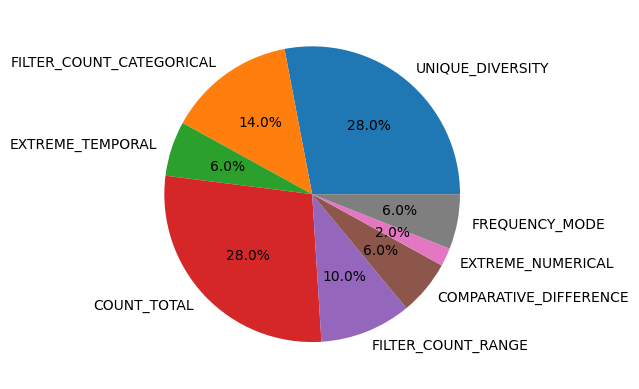

In [275]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_categorical_pie(data):
    counts = Counter(data)
    plt.pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%')

plot_categorical_pie([sample['Strategy'] for sample in question_generator.valid_tables])

In [276]:
for sample in question_generator.valid_tables:
    print(f"Group name: {sample['Group name']}")
    print(f"Strategy: {sample['Strategy']}")
    print(f"Question: {sample['Question']}")
    print(f"Entity column: {sample['Entity column']}")
    print(f"Data column: {sample['Data column']}")
    print(f"Wikipedia page: {sample['Wikipedia page']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Countries where The Pizza Company has international operations, along with their first opening years.
Strategy: UNIQUE_DIVERSITY
Question: How many different countries have The Pizza Company opened in?
Entity column: Country
Data column: Country
Wikipedia page: https://en.wikipedia.org/wiki/The_Pizza_Company#International_operations


,Country,First opening,Cities
0,Thailand,1981,Nationwide
1,China,2004,"Beijing , Shanghai"
2,Malaysia,2005,"Kuala Lumpur , Penang , Sarawak , Malacca and ..."
3,Cambodia,2006,"Phnom Penh , Siem Reap , Battambang , Sihanouk..."
4,Saudi Arabia,2007,"Ad-Dammam , Al-Khobar , Jeddah , Riyadh"
5,United Arab Emirates,2007,Abu Dhabi - Dubai - Sharjah - Fujairah
6,Vietnam,2011,Nationwide
7,Laos,2011,Vientiane
8,Israel,2011,Rishon LeZion
9,Iran,2012,Tehran




Group name: Films that received multiple awards at the 70th Academy Awards.
Strategy: FILTER_COUNT_CATEGORICAL
Question: How many films received 2 awards at the 70th Academy Awards?
Entity column: Film
Data column: Awards
Wikipedia page: https://en.wikipedia.org/wiki/70th_Academy_Awards#Winners_and_nominees


,Awards,Film
0,11,Titanic
1,2,As Good as It Gets
2,2,Good Will Hunting
3,2,L.A. Confidential




Group name: The top languages spoken in Florida as of the 2010 census, ranked by the percentage of the population that speaks each language.
Strategy: UNIQUE_DIVERSITY
Question: How many different languages were spoken in Florida according to the 2010 census?
Entity column: Language
Data column: Language
Wikipedia page: https://en.wikipedia.org/wiki/Demographics_of_Florida#Languages


...

,Preceded by Sweden,World Champions 1968 (1st title),Succeeded by Poland
0,Preceded by Sweden,World Champions 1971 (2nd title) 1972 (3rd tit...,Succeeded by Australia
1,Preceded by Australia,World Champions 1977 (7th title),Succeeded by Denmark
2,Preceded by New Zealand,World Champions 1980 (8th title),Succeeded by Denmark
3,Preceded by Denmark,World Champions 1989 (9th title),Succeeded by United States
4,Preceded by Russia,World Champions 2021 (10th title),Succeeded by Australia
5,Preceded by Poland,World Champions 2024 (11th title),Succeeded by




Group name: The 10 highest-grossing South Korean films released in 2001, ranked by admissions.
Strategy: COUNT_TOTAL
Question: How many distinct films were among the highest-grossing South Korean films released in 2001?
Entity column: Title
Data column: Title
Wikipedia page: https://en.wikipedia.org/wiki/List_of_South_Korean_films_of_2001#Box_office


,Rank,Title,Distributor,Admissions
0,1,Friend,Korea Pictures,8134500
1,2,My Sassy Girl,Cinema Service,4852845
2,3,Kick the Moon,Cinema Service,4353800
3,4,My Wife Is a Gangster,Seo Se-won Production,5180900
4,5,Hi! Dharma!,Cineworld,3746000
5,6,"My Boss, My Hero",CJ Entertainment,3302000
6,7,Guns & Talks,Cinema Service,2227000
7,8,Musa,CJ Entertainment,2067100
8,9,Volcano High,Cinema Service,1687800
9,10,Bungee Jumping of Their Own,Cineclick Asia,947000




Group name: Representatives of the legislative districts of Parañaque during the historical periods of the Philippine Congress.
Strategy: UNIQUE_DIVERSITY
Question: How many different representatives served during the legislative districts of Parañaque across the historical periods of the Philippine Congress?
Entity column: Representative
Data column: Representative
Wikipedia page: https://en.wikipedia.org/wiki/Legislative_districts_of_Parañaque#Historical__districts


,Period,Representative,Constituents
0,8th Congress 1987 – 1992,Freddie N. Webb,Parañaque
1,9th Congress 1992 – 1995,Jose Roilo S. Golez,Parañaque
2,10th Congress 1995 – 1998,Jose Roilo S. Golez,Parañaque
3,11th Congress 1998 – 2001,Jose Roilo S. Golez,Parañaque
4,12th Congress 2001 – 2004,Eduardo C. Zialcita,Parañaque


# Test 0:

In [456]:
from knowledge_maze.create_dataset.create_questions.question_generation import TableSanitizer, StrategySelector

sanitizer = TableSanitizer(random.sample(group_constructor.valid_tables, 200))
sanitizer.process_tables()

selector = StrategySelector(sanitizer.sanitized_tables)
selector.get_strategies()

Sanitizing tables:   0%|          | 0/200 [00:00<?, ?it/s]

Detecting top strategies:   0%|          | 0/200 [00:00<?, ?it/s]

In [513]:
from knowledge_maze.create_dataset.create_questions.question_generation import QuestionGenerator

generator = QuestionGenerator(random.sample(selector.updated_data, 25), strategy_definitions=load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
_ = await generator.generate_questions()

Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/25 [00:00<?, ?it/s]


══════════════════════════════════════════════════
🚀 SEQUENTIAL STRATEGY EXECUTION COMPLETE
══════════════════════════════════════════════════
Initial Tables:      25
Successfully Gen:    25
Exhausted Strats:    0
══════════════════════════════════════════════════


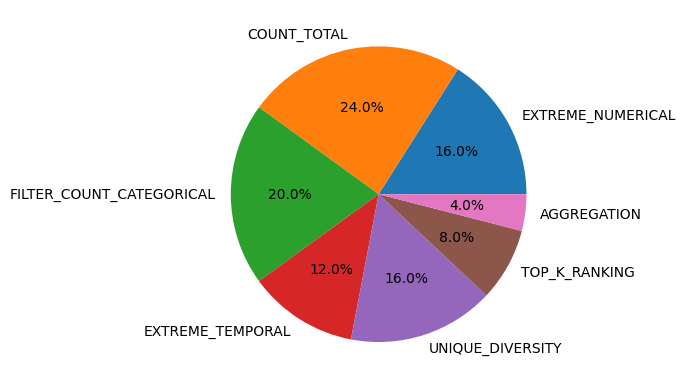

In [514]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_categorical_pie(data):
    counts = Counter(data)
    plt.pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%')

plot_categorical_pie([sample['strategy'] for sample in generator.valid_results])

In [511]:
for sample in generator.valid_results:
    if sample['strategy'] == 'COUNT_TOTAL':
        print(f"Group name: {sample['group_name']}")
        print(f"Wikipedia page: {sample['metadata']['wiki_link']}")
        print(f"Strategy: {sample['strategy']}")
        print(f"Thought: {sample['thought']}")
        print(f"Question: {sample['question']}")
        display(pd.DataFrame(sample['data']))
        print()
        print()

Group name: Rowing clubs from Scotland and their associated blade colors.
Wikipedia page: https://en.wikipedia.org/wiki/List_of_rowing_blades_used_by_schools_and_universities#Scotland
Strategy: COUNT_TOTAL
Thought: The group name specifies rowing clubs from Scotland, which allows for the identification of distinct entities. The data provides a list of rowing clubs, meeting the requirement for a list of entities without specifying a fixed count. Therefore, I can formulate a question that asks for the total number of distinct rowing clubs in Scotland based on the provided data.
Question: How many distinct rowing clubs are there in Scotland based on their associated blade colors?


,Club,Description
0,Aberdeen Schools Rowing Association (ASRA),White with 3 black chevrons
1,George Heriots School Rowing Club,White
2,George Watsons College Rowing Club,White with maroon tip
3,Glasgow Academy Boat Club,White with crest
4,Glasgow Schools Rowing Club,White with crest




Group name: Men's international hockey players associated with the University of Exeter Hockey Club.
Wikipedia page: https://en.wikipedia.org/wiki/University_of_Exeter_Hockey_Club#Notable_players
Strategy: COUNT_TOTAL
Thought: The group name specifies men's international hockey players associated with the University of Exeter Hockey Club, which allows for the counting of distinct players. The data provided lists individual players without any fixed count or specification that would violate the requirements. Therefore, a question can be formulated to inquire about the total number of distinct players in this group.
Question: How many distinct men's international hockey players are associated with the University of Exeter Hockey Club?


,Player,Events/Notes
0,Rhys Bradshaw,CG (2022)
1,James Carleton,EC (2025)
2,Ben Galloway,Nations Cup 2025
3,Peter Swainson,2002-2006
4,Sam Taylor,2025




Group name: Transcription factors associated with the regulation of the SLC66A3 gene.
Wikipedia page: https://en.wikipedia.org/wiki/SLC66A3#Gene_level_regulation
Strategy: COUNT_TOTAL
Thought: The group name specifies transcription factors associated with a specific gene, and the data provides a list of distinct transcription factors. This aligns with the COUNT_TOTAL strategy, as it allows for the formulation of a question regarding the total number of distinct entities without specifying a fixed count. The question is clear and professional, meeting all requirements.
Question: How many distinct transcription factors are associated with the regulation of the SLC66A3 gene?


,Transcription factor,Function
0,RNA polymerase II transcription factor II B,Stimulation of transcription initiation.
1,EVI1-myleoid transforming protein,Involved in the proliferation and differentiat...
2,Krueppel like transcription factors,Involved in β-globin expression and the develo...
3,GATA binding factors,Involved in the regulation of transcription du...


# Test:

In [313]:
from knowledge_maze.create_dataset.create_questions.question_generation import QuestionGenerator

question_generator = QuestionGenerator(random.sample(group_constructor.valid_tables, 50), 
                                       strategies=load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
_ = await question_generator.generate_questions()

--- Round 1: Processing 50 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/50 [00:00<?, ?it/s]

--- Round 2: Processing 17 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/17 [00:00<?, ?it/s]

--- Round 3: Processing 8 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/8 [00:00<?, ?it/s]


══════════════════════════════════════════════════
🚀 QUESTION GENERATION COMPLETE
══════════════════════════════════════════════════
Initial Tables:      50
Successfully Gen:    45
Failed (3 Rounds):   5
══════════════════════════════════════════════════


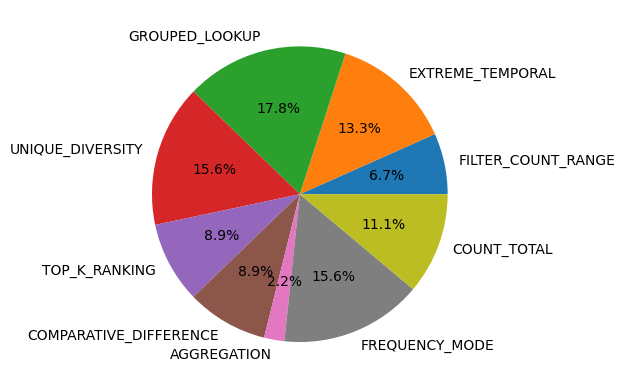

In [314]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_categorical_pie(data):
    counts = Counter(data)
    plt.pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%')

plot_categorical_pie([sample['strategy'] for sample in question_generator.valid_results])

In [318]:
for sample in question_generator.valid_results:
    if sample['strategy'] == "TOP_K_RANKING":
        print(f"Group name: {sample['group_name']}")
        print(f"Wikipedia page: {sample['metadata']['wiki_page']}")
        print(f"Strategy: {sample['strategy']}")
        print(f"Thought: {sample['thought']}")
        print(f"Question: {sample['question']}")
        print(f"Answer map:")
        display(pd.DataFrame.from_dict(sample['answer_map'], orient="index", columns=["Data"]))
        print()
        print()

Group name: Films that received multiple nominations at the 27th Independent Spirit Awards, along with their nomination counts.
Wikipedia page: https://en.wikipedia.org/wiki/27th_Independent_Spirit_Awards#Winners_and_nominees
Strategy: TOP_K_RANKING
Thought: The data includes a numerical column 'Nominations' which allows for ranking the films based on the number of nominations they received. This meets the requirements for the TOP_K_RANKING strategy, as I can identify the top films based on their nomination counts.
Question: What are the five films that received the most nominations at the 27th Independent Spirit Awards?
Answer map:


,Data
The Artist,5
Beginners,4
The Descendants,4
Drive,4
Take Shelter,4
50/50,3
Martha Marcy May Marlene,3
Another Earth,2
Cedar Rapids,2
Margin Call,2




Group name: Nationalities of ownership of garment factories in Cambodia as of 2010.
Wikipedia page: https://en.wikipedia.org/wiki/Economy_of_Cambodia#Economic_sectors
Strategy: TOP_K_RANKING
Thought: The data includes a numerical column 'Number of factories owned' which allows for ranking the nationalities based on their ownership. The question is framed to identify the top nationalities based on the number of factories they own, adhering to the TOP_K_RANKING strategy.
Question: What are the top three nationalities of ownership of garment factories in Cambodia based on the number of factories owned as of 2010?
Answer map:


,Data
Taiwan,66
China,44
Hong Kong,39
South Korea,31
Malaysia,14
Cambodia,13
Singapore,10
USA,9
Others,10




Group name: The 10 highest-grossing films based on comic strips, ranked by their worldwide gross revenue.
Wikipedia page: https://en.wikipedia.org/wiki/List_of_films_based_on_comic_strips#Highest_grossing_comic_strip_films
Strategy: TOP_K_RANKING
Thought: The data includes a numerical column 'Worldwide gross' which allows for ranking the films based on their gross revenue. The question is framed to identify the top films based on this metric, fulfilling the requirements of the TOP_K_RANKING strategy.
Question: What are the top five highest-grossing films based on comic strips according to their worldwide gross revenue?
Answer map:


,Data
The Smurfs,"$563,892,376"
Over the Hedge,"$339,795,890"
The Garfield Movie,"$257,211,259"
The Peanuts Movie,"$246,233,113"
Garfield: The Movie,"$203,172,417"
Smurfs: The Lost Village,"$197,183,546"
Dick Tracy,"$162,738,726"
Garfield: A Tail of Two Kitties,"$143,325,970"
Annie,"$136,853,506"
Smurfs,"$123,700,574"




Group name: Grammy Awards received by Chris Rock for Best Comedy Album.
Wikipedia page: https://en.wikipedia.org/wiki/List_of_awards_and_nominations_received_by_Chris_Rock#Main_awards
Strategy: TOP_K_RANKING
Thought: The data includes a clear numerical column, which is the count of Grammy Awards won by Chris Rock for Best Comedy Album. This allows for the identification of the top works based on the number of wins. The question is framed to focus on the top works based on this criterion.
Question: What are the three Grammy Award-winning comedy albums by Chris Rock?
Answer map:


,Data
Chris Rock: Roll with the New,Chris Rock: Roll with the New
Chris Rock: Bigger & Blacker,Chris Rock: Bigger & Blacker
Chris Rock: Never Scared,Chris Rock: Never Scared
Chris Rock: Tamborine,Chris Rock: Tamborine
Chris Rock: Selective Outrage,Chris Rock: Selective Outrage


In [371]:
from knowledge_maze.create_dataset.create_questions.question_generation import StrategySelector
strategy_selector = StrategySelector(group_constructor.valid_tables)
# sample = random.sample(group_constructor.valid_tables, 1)[0]
updated_data = await strategy_selector.batch_select_strategies()

Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/456 [00:00<?, ?it/s]

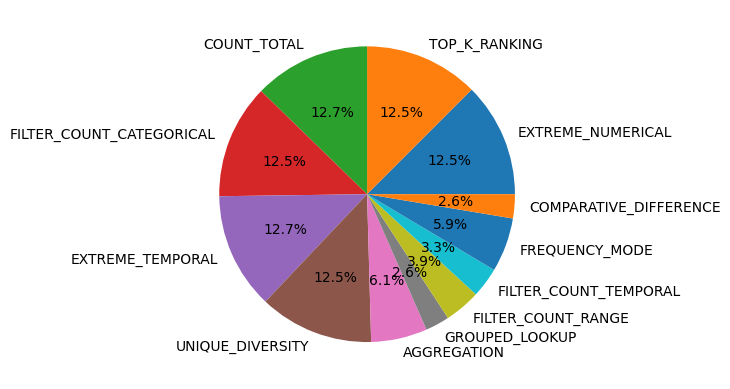

In [372]:
strategies = [s['strategy'] for s in updated_data[0]]
plot_categorical_pie(strategies)

In [394]:
for samp in updated_data[0]:
    if samp['strategy'] == "EXTREME_TEMPORAL":
        print(f"Name: {samp['table_name']}")
        print(f"Strategy: {samp['strategy']}")
        print(f"Reasoning: {samp['reasoning']}")
        print(f"Table data: \n{samp['table_data']}")
        # display(pd.DataFrame(samp['table_data']))

Name: Films awarded at the 2007 Toronto International Film Festival, including their respective awards and directors.
Strategy: EXTREME_TEMPORAL
Reasoning: Although the data is not strictly temporal, we can creatively interpret the awards as having a timeline. A question could be framed around identifying the film that won the highest award, which adds an interesting layer of competition and context to the trivia.
Table data: 
[{'Award': "People's Choice Award", 'Film': 'Eastern Promises', 'Director': 'David Cronenberg'}, {'Award': "People's Choice Award, First Runner Up", 'Film': 'Juno', 'Director': 'Jason Reitman'}, {'Award': "People's Choice Award, Second Runner Up", 'Film': 'Body of War', 'Director': 'Ellen Spiro , Phil Donahue'}, {'Award': 'Best Canadian Feature Film', 'Film': 'My Winnipeg', 'Director': 'Guy Maddin'}, {'Award': 'Best Canadian First Feature Film', 'Film': 'Continental, a Film Without Guns (Continental, un film sans fusil)', 'Director': 'Stéphane Lafleur'}, {'Award'

In [401]:
from knowledge_maze.create_dataset.create_questions.question_generation import StrategySelector
strategy_selector = StrategySelector(group_constructor.valid_tables)
sample = random.sample(group_constructor.valid_tables, 1)[0]
st = strategy_selector.get_valid_strategies(sample)

strategiessss = set(["AGGREGATION", "COMPARATIVE_DIFFERENCE", "GROUPED_LOOKUP", "FREQUENCY_MODE", "FILTER_COUNT_RANGE", 
                     "TOP_K_RANKING", "UNIQUE_DIVERSITY", "EXTREME_NUMERIC", "EXTREME_TEMPORAL", "UNIQUE_LOOKUP", "COUNT_TOTAL"])

print(sample['Group name'])
print(sample['Wikipedia page'])
display(pd.DataFrame(sample['Table data']))
print(f"Selected strategies: {st}")
print(f"Discarded strategies: {list(strategiessss - set(st))}")

Men's singles badminton tournament achievements of Peter Rasmussen in the IBF World Grand Prix.
https://en.wikipedia.org/wiki/Peter_Rasmussen_(badminton)#Achievements


,Year,Tournament,Opponent,Score,Result
0,1993,Finnish Open,Peter Espersen,"4–15, 5–15",Runner-up
1,1994,Dutch Open,Poul-Erik Høyer Larsen,"7–15, 7–15",Runner-up
2,1997,Japan Open,Park Sung-woo,"15–3, 15–1",Winner
3,2002,U.S. Open,Peter Gade,"14–17, 17–15, 1–15",Runner-up
4,2002,Puerto Rico Open,Yousuke Nakanishi,"15–4, 15–5",Winner
5,2004,U.S. Open,Kendrick Lee,"7–12, retired",Runner-up


Selected strategies: ['AGGREGATION', 'EXTREME_NUMERIC', 'UNIQUE_LOOKUP', 'EXTREME_TEMPORAL', 'COMPARATIVE_DIFFERENCE', 'TOP_K_RANKING', 'FILTER_COUNT_RANGE', 'UNIQUE_DIVERSITY', 'COUNT_TOTAL', 'FREQUENCY_MODE']
Discarded strategies: ['GROUPED_LOOKUP']


In [399]:
from knowledge_maze.create_dataset.create_questions.question_generation import StrategySelector
strategy_selector = StrategySelector(group_constructor.valid_tables)
sample = random.sample(group_constructor.valid_tables, 1)[0]
st = strategy_selector.get_valid_strategies(sample)

strategiessss = set(["AGGREGATION", "COMPARATIVE_DIFFERENCE", "GROUPED_LOOKUP", "FREQUENCY_MODE", "FILTER_COUNT_RANGE", 
                     "TOP_K_RANKING", "UNIQUE_DIVERSITY", "EXTREME_NUMERIC", "EXTREME_TEMPORAL", "UNIQUE_LOOKUP", "COUNT_TOTAL"])

print(sample['Group name'])
print(sample['Wikipedia page'])
display(pd.DataFrame(sample['Table data']))
print(f"Selected strategies: {st}")
print(f"Discarded strategies: {list(strategiessss - set(st))}")

Awards and nominations received by Vino G. Bastian for Best Actor at the Indonesian Film Festival.
https://en.wikipedia.org/wiki/List_of_awards_and_nominations_received_by_Vino_G._Bastian#Indonesian_Film_Festival


,Year,Category,Nominated work,Result
0,2008,Best Actor,Radit dan Jani,Won
1,2009,Best Actor,Serigala Terakhir,Nominated
2,2014,Best Actor,3 Nafas Likas,Nominated
3,2015,Best Actor,Toba Dreams,Nominated
4,2016,Best Actor,Warkop DKI Reborn: Jangkrik Boss! Part 1,Nominated
5,2018,Best Actor,Chrisye,Nominated
6,2022,Best Actor,Miracle in Cell No. 7,Nominated


Selected strategies: ['UNIQUE_LOOKUP', 'EXTREME_TEMPORAL', 'COMPARATIVE_DIFFERENCE', 'FILTER_COUNT_RANGE', 'UNIQUE_DIVERSITY', 'COUNT_TOTAL', 'FREQUENCY_MODE']
Discarded strategies: ['TOP_K_RANKING', 'AGGREGATION', 'GROUPED_LOOKUP', 'EXTREME_NUMERIC']
